In [2]:
import pandas as pd

df = pd.read_csv("haberman.csv")
df.columns = ["age", "year", "nodes", "status"]

print(df.dtypes)
print(df.head(60))

age       int64
year      int64
nodes     int64
status    int64
dtype: object
    age  year  nodes  status
0    30    64      1       1
1    30    62      3       1
2    30    65      0       1
3    31    59      2       1
4    31    65      4       1
5    33    58     10       1
6    33    60      0       1
7    34    59      0       2
8    34    66      9       2
9    34    58     30       1
10   34    60      1       1
11   34    61     10       1
12   34    67      7       1
13   34    60      0       1
14   35    64     13       1
15   35    63      0       1
16   36    60      1       1
17   36    69      0       1
18   37    60      0       1
19   37    63      0       1
20   37    58      0       1
21   37    59      6       1
22   37    60     15       1
23   37    63      0       1
24   38    69     21       2
25   38    59      2       1
26   38    60      0       1
27   38    60      0       1
28   38    62      3       1
29   38    64      1       1
30   38    66      0   

 Data Inspection & Overview

In [3]:
print(df.shape)
print("________________")
print(df.isna().sum())
print("________________")
print(df["status"].value_counts())
print("________________")
print(df.describe())

(306, 4)
________________
age       0
year      0
nodes     0
status    0
dtype: int64
________________
status
1    225
2     81
Name: count, dtype: int64
________________
              age        year       nodes      status
count  306.000000  306.000000  306.000000  306.000000
mean    52.457516   62.852941    4.026144    1.264706
std     10.803452    3.249405    7.189654    0.441899
min     30.000000   58.000000    0.000000    1.000000
25%     44.000000   60.000000    0.000000    1.000000
50%     52.000000   63.000000    1.000000    1.000000
75%     60.750000   65.750000    4.000000    2.000000
max     83.000000   69.000000   52.000000    2.000000


Target Binary Encoding

In [4]:
df["status"] = (df["status"] == 2).astype(int)
print(df["status"].value_counts())

status
0    225
1     81
Name: count, dtype: int64


Data Visualization & Feature Distribution

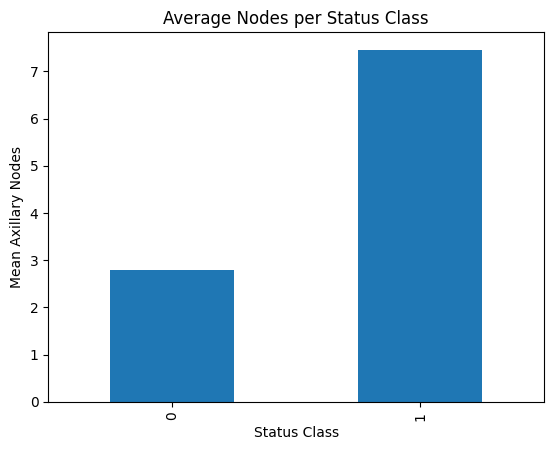

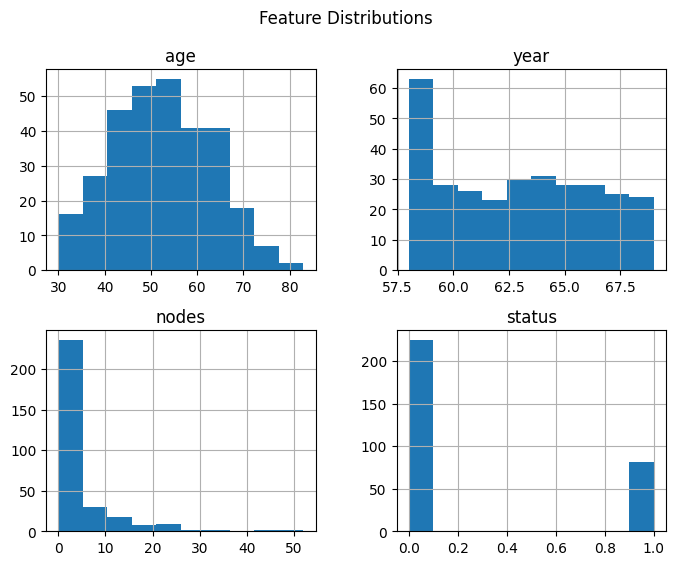

In [5]:
import matplotlib.pyplot as plt

df.groupby("status")["nodes"].mean().plot(kind="bar")
plt.title("Average Nodes per Status Class")
plt.xlabel("Status Class")
plt.ylabel("Mean Axillary Nodes")
plt.show()

df.hist(figsize=(8, 6))
plt.suptitle("Feature Distributions")
plt.show()

Train-Test Data Splitting

In [6]:
from sklearn.model_selection import train_test_split

X = df[["age", "year", "nodes"]]
y = df["status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

 Logistic Regression Model Baseline

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

df = pd.read_csv("haberman.csv")
df.columns = ["age", "year", "nodes", "status"]
df["status"] = (df["status"] == 2).astype(int)

X = df.drop("status", axis=1)
y = df["status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("y_train:", y_train.value_counts().to_dict())

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)
model.fit(X_train, y_train)

preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, preds)
print(cm)
print(classification_report(y_test, preds))
print("AUC:", roc_auc_score(y_test, probs))
print("Specificity:", cm[0, 0] / (cm[1, 0] + cm[1, 1]))
print("Specifivity:", cm[1, 1] / (cm[0, 0] + cm[0, 1]))

y_train: {0: 179, 1: 65}
[[36 10]
 [12  4]]
              precision    recall  f1-score   support

           0       0.75      0.78      0.77        46
           1       0.29      0.25      0.27        16

    accuracy                           0.65        62
   macro avg       0.52      0.52      0.52        62
weighted avg       0.63      0.65      0.64        62

AUC: 0.53125
Specificity: 2.25
Specifivity: 0.08695652173913043


Model Validation using Cross-Validation

In [8]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
scores = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
print(scores.mean(), scores.std())

0.6859297385620916 0.07161434310801693


 Random Forest Classifier & Evaluation

In [9]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300, max_depth=3,
    class_weight="balanced", random_state=42,
)
scores_rf = cross_val_score(rf, X, y, cv=cv, scoring="roc_auc")
print(scores_rf.mean(), scores_rf.std())

0.7107058823529413 0.060985108426086725


Feature Skewness Correction using Log Transform

In [10]:
import numpy as np
X2 = X.copy()
X2["nodes"] = np.log1p(X2["nodes"])
print(cross_val_score(model, X2, y, cv=cv, scoring="roc_auc").mean())

0.703485294117647


Gradio Web App Interface for Model Deployment

In [ ]:

import gradio as gr
import pandas as pd

THRESHOLD = 0.5

def predict(age, year, nodes):
    case = pd.DataFrame([[age, year, nodes]], columns=["age", "year", "nodes"])


    prob = model.predict_proba(case)[0, 1]

    decision = "Higher risk" if prob >= THRESHOLD else "Lower risk"
    return f"{prob:.0%}", decision

demo = gr.Interface(
    fn=predict,
    inputs=[
        gr.Slider(30, 85, value=52, step=1, label="Age"),
        gr.Slider(58, 69, value=63, step=1, label="Year of operation (19XX)"),
        gr.Slider(0, 52, value=5, step=1, label="Positive axillary nodes")
    ],
    outputs=[
        gr.Textbox(label="Relative risk score"),
        gr.Textbox(label="Decision")
    ],
    title="Haberman Survival Model (Educational Use Only)",
    flagging_mode="never"
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://fc079b2ee088d42d94.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
